In [ ]:
#Setup e importaciones (correr una vez)
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Para modelo prediccion
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm

# El CSV debe estar en la misma carpeta que este notebook.
BASE_DIR = Path.cwd()
CSV_PATH = BASE_DIR / "AB_NYC_2019.csv"
if not CSV_PATH.exists():
    CSV_PATH = Path("C:/Users/apala/Downloads/mineria_airbnb/AB_NYC_2019.csv")

df = pd.read_csv(CSV_PATH)
df.columns = [column.strip() for column in df.columns]
df = df.loc[df["price"] > 0].copy()
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

OUT = BASE_DIR / "outputs_airbnb"
OUT.mkdir(exist_ok=True)

def save_table(table_df, name):
    table_df.to_csv(OUT / f"{name}.csv", index=False)
    print(f"Tabla guardada: {OUT / f'{name}.csv'}")

print(f"Dataset cargado: {df.shape[0]:,} filas y {df.shape[1]} columnas")

Dataset cargado: 48,884 filas y 16 columnas


In [16]:
#Vista inicial del dataset
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,0.00,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [17]:
# === BLOQUE 0.5: Preparación de columnas numéricas para Airbnb ===

# Variables numéricas disponibles para el resumen, correlación y PCA.
candidatas_numericas = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "latitude",
    "longitude",
]
num_cols = [
    column for column in candidatas_numericas
    if column in df.columns and df[column].notna().sum() > 0
]

# Variables categóricas que se utilizarán en los gráficos y el modelo.
cat_cols = [
    column for column in ["neighbourhood_group", "neighbourhood", "room_type"]
    if column in df.columns
]

print("Columnas numéricas:", num_cols)
print("Columnas categóricas:", cat_cols)

# === BLOQUE 1: Tabla resumen de medidas estadísticas ===
resumen = []
n_total = len(df)

for column in num_cols:
    x_all = df[column]
    x = x_all.dropna()
    obs = len(x)
    media = x.mean() if obs else np.nan
    desviacion = x.std(ddof=1) if obs > 1 else np.nan
    resumen.append({
        "Variable": column,
        "Obs": obs,
        "% Missing": 100 * (1 - obs / n_total) if n_total else np.nan,
        "Media": media,
        "Mediana": x.median() if obs else np.nan,
        "Q1": x.quantile(0.25) if obs else np.nan,
        "Q3": x.quantile(0.75) if obs else np.nan,
        "Min": x.min() if obs else np.nan,
        "Max": x.max() if obs else np.nan,
        "DE": desviacion,
        "CV %": 100 * desviacion / media if media else np.nan,
        "Asimetria": stats.skew(x, bias=False) if obs >= 3 else np.nan,
    })

tabla_resumen = pd.DataFrame(resumen).round(3)
display(tabla_resumen)
save_table(tabla_resumen, "tabla_resumen_estadisticas")

Columnas numéricas: ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'latitude', 'longitude']
Columnas categóricas: ['neighbourhood_group', 'neighbourhood', 'room_type']


,Variable,Obs,% Missing,Media,Mediana,Q1,Q3,Min,Max,DE,CV %,Asimetria
0,price,48884,0.0,152.755,106.000,69.000,175.000,10.000,10000.000,240.170,157.226,19.119
1,minimum_nights,48884,0.0,7.030,3.000,1.000,5.000,1.000,1250.000,20.512,291.786,21.827
2,number_of_reviews,48884,0.0,23.272,5.000,1.000,24.000,0.000,629.000,44.551,191.438,3.691
3,reviews_per_month,48884,0.0,1.091,0.370,0.040,1.580,0.000,58.500,1.597,146.426,3.302
4,calculated_host_listings_count,48884,0.0,7.145,1.000,1.000,2.000,1.000,327.000,32.956,461.272,7.932
5,availability_365,48884,0.0,112.779,45.000,0.000,227.000,0.000,365.000,131.627,116.712,0.763
6,latitude,48884,0.0,40.729,40.723,40.690,40.763,40.500,40.913,0.055,0.134,0.237
7,longitude,48884,0.0,-73.952,-73.956,-73.983,-73.936,-74.244,-73.713,0.046,-0.062,1.285


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\tabla_resumen_estadisticas.csv


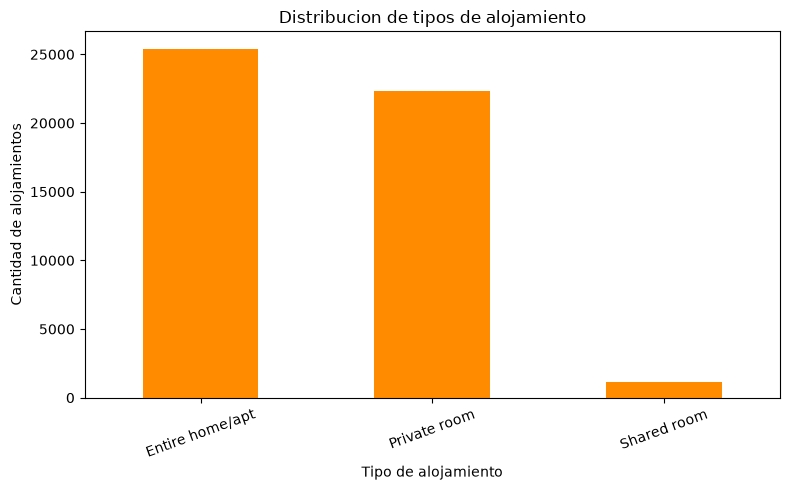

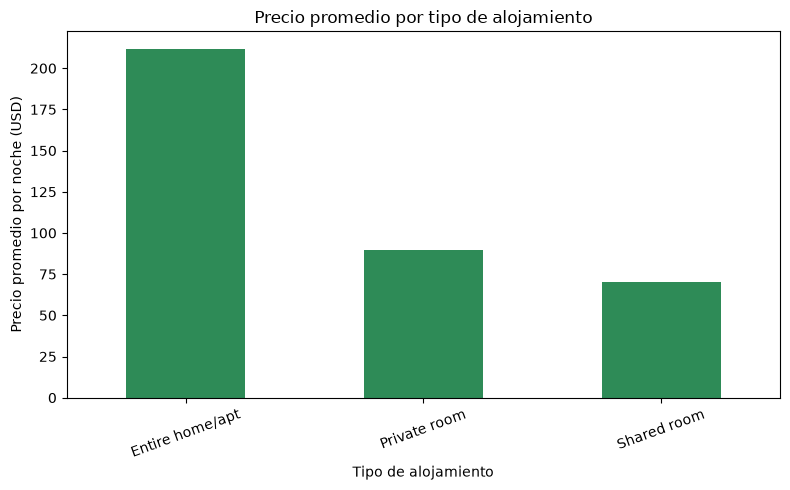

In [18]:
# === BLOQUE 2: Grafico de barras de una variable categorica ===

cat_col = "room_type"
conteos = df[cat_col].value_counts(dropna=False).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
conteos.plot(kind="bar", color="darkorange")
plt.title("Distribucion de tipos de alojamiento")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Cantidad de alojamientos")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUT / "barras_room_type.png", dpi=150)
plt.show()

# Precio promedio por tipo de alojamiento.
precio_promedio = df.groupby(cat_col)["price"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
precio_promedio.plot(kind="bar", color="seagreen")
plt.title("Precio promedio por tipo de alojamiento")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Precio promedio por noche (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUT / "precio_promedio_room_type.png", dpi=150)
plt.show()

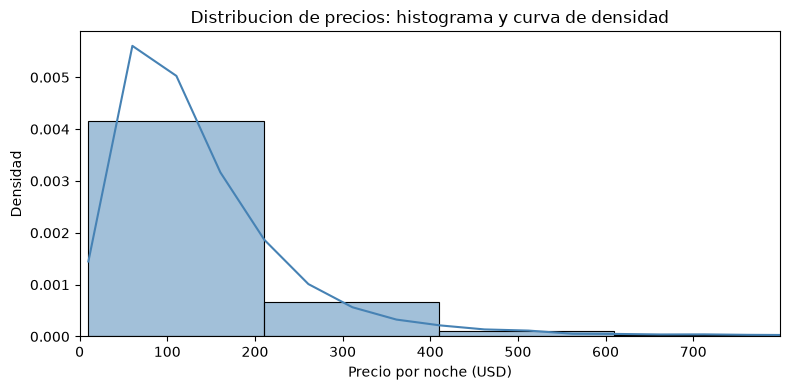

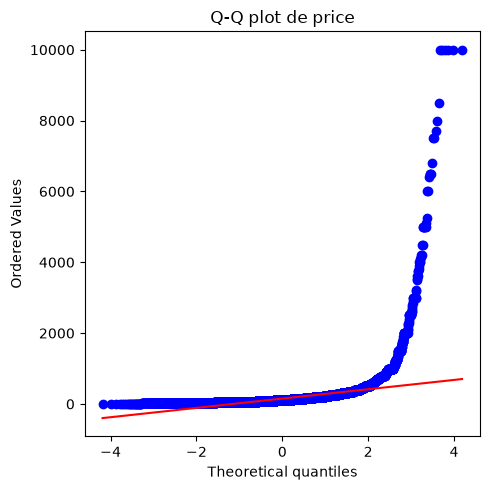

,Prueba,Estadistico,p-valor,Conclusion
0,Kolmogorov-Smirnov,0.2834,0.0,Rechaza normalidad
1,Shapiro-Wilk,0.3420,0.0,Rechaza normalidad


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\tabla_normalidad_price.csv


In [19]:
# === BLOQUE 3: Histograma, densidad y normalidad de price ===
x = df["price"].dropna()

plt.figure(figsize=(8, 4))
sns.histplot(x, bins=50, stat="density", kde=True, color="steelblue")
plt.title("Distribucion de precios: histograma y curva de densidad")
plt.xlabel("Precio por noche (USD)")
plt.ylabel("Densidad")
plt.xlim(0, x.quantile(0.99))
plt.tight_layout()
plt.savefig(OUT / "histograma_precio.png", dpi=150)
plt.show()

plt.figure(figsize=(5, 5))
stats.probplot(x, dist="norm", plot=plt)
plt.title("Q-Q plot de price")
plt.tight_layout()
plt.savefig(OUT / "qqplot_precio.png", dpi=150)
plt.show()

# Pruebas de normalidad sobre una muestra para mantener el calculo manejable.
sample = x.sample(min(5000, len(x)), random_state=42)
x_std = (sample - sample.mean()) / sample.std(ddof=1)
ks_stat, ks_p = stats.kstest(x_std, "norm")
sh_stat, sh_p = stats.shapiro(sample)

tabla_norm = pd.DataFrame({
    "Prueba": ["Kolmogorov-Smirnov", "Shapiro-Wilk"],
    "Estadistico": [ks_stat, sh_stat],
    "p-valor": [ks_p, sh_p],
    "Conclusion": [
        "Rechaza normalidad" if ks_p < 0.05 else "No rechaza normalidad",
        "Rechaza normalidad" if sh_p < 0.05 else "No rechaza normalidad",
    ],
})
display(tabla_norm.round(4))
save_table(tabla_norm.round(4), "tabla_normalidad_price")

,Tipo de outlier,Cantidad,% del total
0,Inferiores,0,0.00
1,Superiores,2972,6.08


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\tabla_outliers_price.csv


C:\Users\apala\AppData\Local\Temp\ipykernel_14168\53326922.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(x, vert=True)


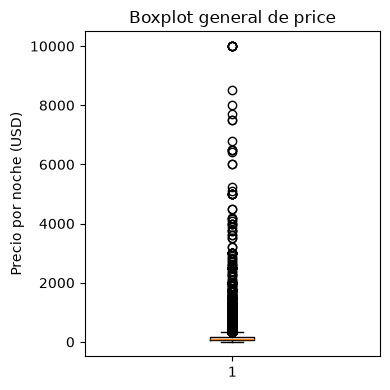

<Figure size 800x500 with 0 Axes>

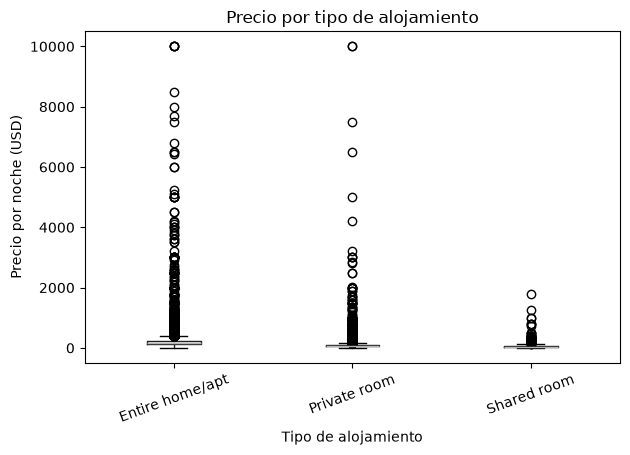

In [20]:
# === BLOQUE 4: Outliers de price mediante IQR ===

x = df["price"].dropna()
Q1, Q3 = x.quantile(0.25), x.quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

out_inf = (x < lower).sum()
out_sup = (x > upper).sum()
tabla_outliers = pd.DataFrame({
    "Tipo de outlier": ["Inferiores", "Superiores"],
    "Cantidad": [out_inf, out_sup],
    "% del total": [100 * out_inf / len(x), 100 * out_sup / len(x)],
})

display(tabla_outliers.round(3))
save_table(tabla_outliers.round(3), "tabla_outliers_price")

plt.figure(figsize=(4, 4))
plt.boxplot(x, vert=True)
plt.title("Boxplot general de price")
plt.ylabel("Precio por noche (USD)")
plt.tight_layout()
plt.savefig(OUT / "boxplot_price_general.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
df.boxplot(column="price", by="room_type", grid=False)
plt.title("Precio por tipo de alojamiento")
plt.suptitle("")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Precio por noche (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUT / "boxplot_price_by_room_type.png", dpi=150)
plt.show()

,Variable,% Missing
12,last_review,20.561
3,host_name,0.043
1,name,0.033
0,id,0.000
4,neighbourhood_group,0.000
5,neighbourhood,0.000
6,latitude,0.000
2,host_id,0.000
7,longitude,0.000
8,room_type,0.000


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\tabla_missing.csv


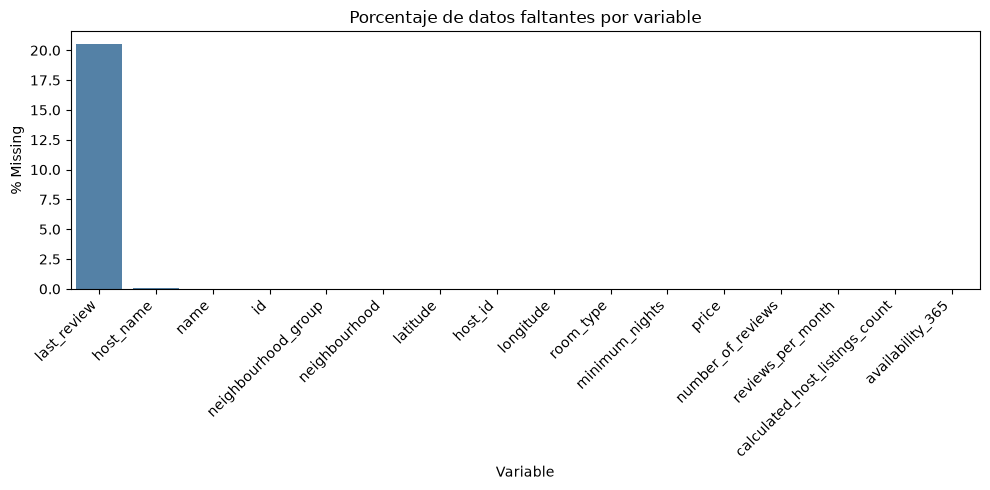

In [26]:
# === BLOQUE 5: Analisis de valores faltantes ===

missing_pct = (
    df.isna()
    .mean()
    .mul(100)
    .reset_index()
    .rename(columns={"index": "Variable", 0: "% Missing"})
    .sort_values("% Missing", ascending=False)
)

display(missing_pct.round(3))
save_table(missing_pct.round(3), "tabla_missing")

plt.figure(figsize=(10, 5))
sns.barplot(data=missing_pct, x="Variable", y="% Missing", color="steelblue")
plt.title("Porcentaje de datos faltantes por variable")
plt.xlabel("Variable")
plt.ylabel("% Missing")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUT / "missing_values_barras.png", dpi=150)
plt.show()

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude
price,1.000,0.043,-0.048,-0.051,0.057,0.082,0.034,-0.150
minimum_nights,0.043,1.000,-0.080,-0.125,0.128,0.144,0.025,-0.063
number_of_reviews,-0.048,-0.080,1.000,0.589,-0.072,0.172,-0.015,0.059
reviews_per_month,-0.051,-0.125,0.589,1.000,-0.047,0.164,-0.019,0.138
calculated_host_listings_count,0.057,0.128,-0.072,-0.047,1.000,0.226,0.020,-0.115
availability_365,0.082,0.144,0.172,0.164,0.226,1.000,-0.011,0.083
latitude,0.034,0.025,-0.015,-0.019,0.020,-0.011,1.000,0.085
longitude,-0.150,-0.063,0.059,0.138,-0.115,0.083,0.085,1.000


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\matriz_correlacion.csv


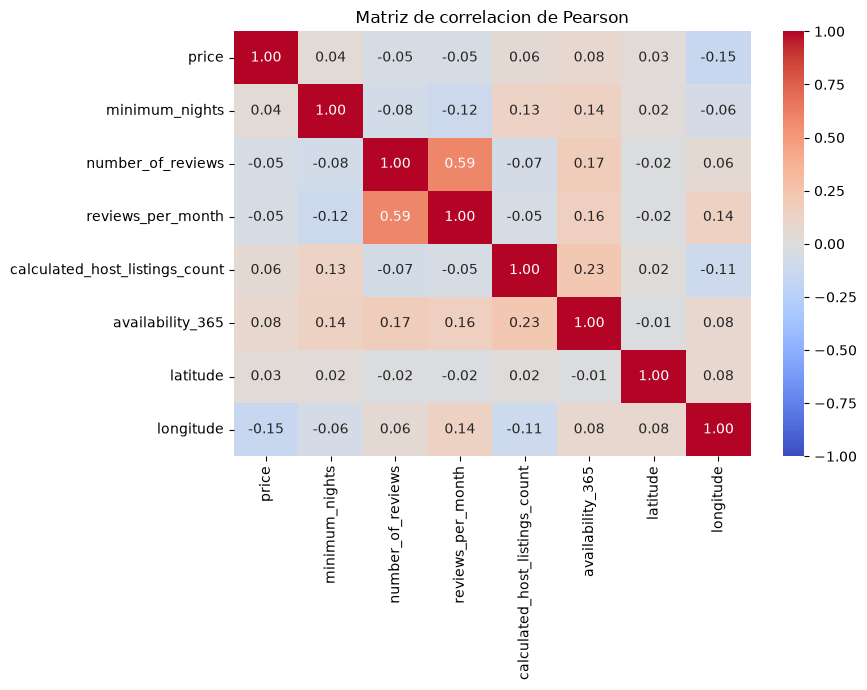

In [27]:
#Correlacion de Pearson entre variables numericas

num_cols_validas = [
    column for column in num_cols
    if df[column].notna().sum() > 0
]
corr = df[num_cols_validas].corr(method="pearson")

display(corr.round(3))
save_table(corr.round(3).reset_index(), "matriz_correlacion")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de correlacion de Pearson")
plt.tight_layout()
plt.savefig(OUT / "heatmap_correlacion.png", dpi=150)
plt.show()

,Componente,Varianza explicada %
0,PC1,24.75
1,PC2,17.23


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\pca_varianza_explicada.csv


,PC1,PC2
price,-0.114,0.533
minimum_nights,-0.153,0.553
number_of_reviews,0.634,0.083
reviews_per_month,0.652,0.014
availability_365,0.279,0.559
latitude,-0.017,-0.007
longitude,0.240,-0.301


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\pca_loadings.csv


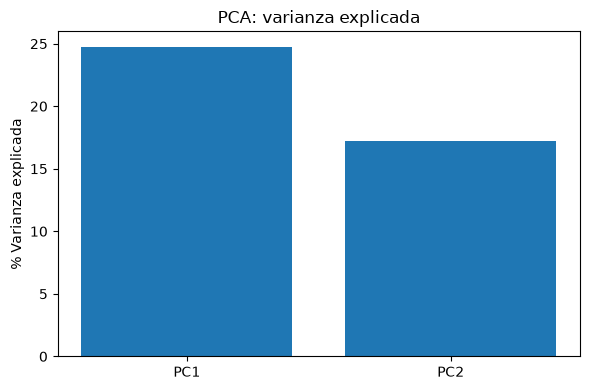

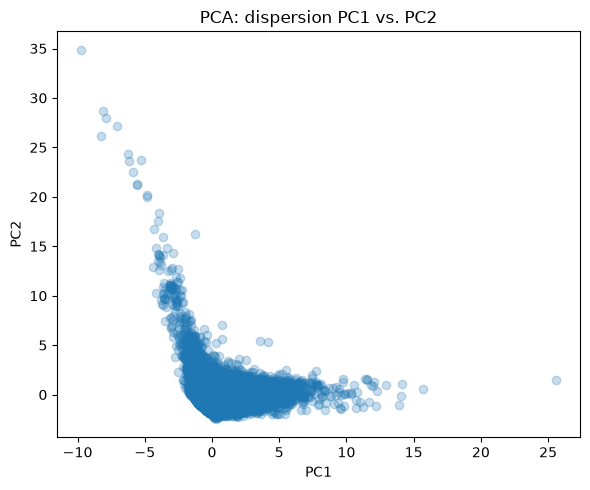

In [23]:
#BLOQUE 7: PCA con estandarizacion

pca_cols = [
    column for column in [
        "price",
        "minimum_nights",
        "number_of_reviews",
        "reviews_per_month",
        "availability_365",
        "latitude",
        "longitude",
    ]
    if column in df.columns
]

X_pca = df[pca_cols].dropna()
if X_pca.shape[0] < 3 or len(pca_cols) < 2:
    raise ValueError("No hay suficientes variables o filas para ejecutar PCA.")

Xs = StandardScaler().fit_transform(X_pca)
pca = PCA(n_components=2, random_state=42)
Xp = pca.fit_transform(Xs)

tabla_pca = pd.DataFrame({
    "Componente": ["PC1", "PC2"],
    "Varianza explicada %": pca.explained_variance_ratio_ * 100,
}).round(2)
display(tabla_pca)
save_table(tabla_pca, "pca_varianza_explicada")

loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_cols,
    columns=["PC1", "PC2"],
).round(3)
display(loadings)
save_table(loadings.reset_index().rename(columns={"index": "Variable"}), "pca_loadings")

plt.figure(figsize=(6, 4))
plt.bar(tabla_pca["Componente"], tabla_pca["Varianza explicada %"])
plt.ylabel("% Varianza explicada")
plt.title("PCA: varianza explicada")
plt.tight_layout()
plt.savefig(OUT / "pca_varianza.png", dpi=150)
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(Xp[:, 0], Xp[:, 1], alpha=0.25)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: dispersion PC1 vs. PC2")
plt.tight_layout()
plt.savefig(OUT / "pca_dispersion.png", dpi=150)
plt.show()

,Modelo,R2,MAE_USD,RMSE_USD
0,Regresion lineal,0.1258,73.0145,187.077


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\tabla_desempeno_modelo.csv

Coeficientes del modelo:
minimum_nights: -0.081498
number_of_reviews: -0.243625
reviews_per_month: -3.104644
calculated_host_listings_count: -0.181365
availability_365: 0.197288
latitude: -218.245655
longitude: -514.183238
neighbourhood_group_Brooklyn: -39.089712
neighbourhood_group_Manhattan: 25.594550
neighbourhood_group_Queens: -7.900844
neighbourhood_group_Staten Island: -158.970878
room_type_Private room: -106.654852
room_type_Shared room: -144.406654
Intercepto: -28935.392689


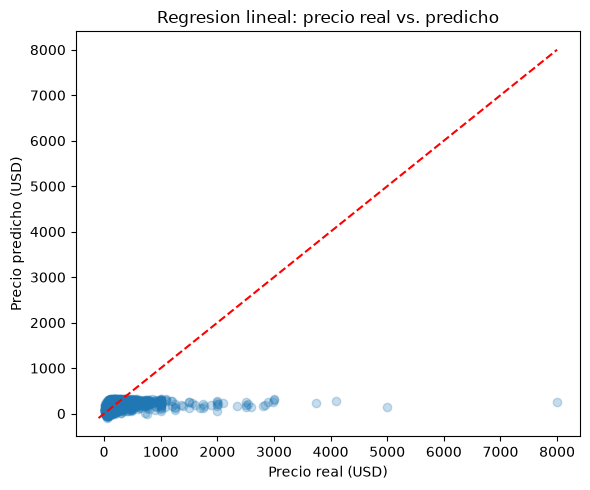


Predicciones de precio por noche:
Alojamiento 1: $273.81 USD
Alojamiento 2: $77.81 USD
Alojamiento 3: $221.76 USD
Alojamiento 4: $67.04 USD


In [24]:
#Modelo de regresión lineal para predecir price

pred_cols = [
    "neighbourhood_group",
    "room_type",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "latitude",
    "longitude",
]
pred_cols = [column for column in pred_cols if column in df.columns]

# Crear variables dummy para las columnas categóricas.
dfe = pd.get_dummies(
    df[pred_cols + ["price"]],
    columns=[column for column in ["neighbourhood_group", "room_type"] if column in pred_cols],
    drop_first=True,
    dtype=float,
).dropna()

y = dfe["price"].astype(float)
X = dfe.drop(columns=["price"]).astype(float)

# Separar datos para medir el rendimiento en alojamientos no vistos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)

mae = mean_absolute_error(y_test, predicciones)
rmse = mean_squared_error(y_test, predicciones) ** 0.5
r2 = r2_score(y_test, predicciones)

tabla_perf = pd.DataFrame({
    "Modelo": ["Regresion lineal"],
    "R2": [r2],
    "MAE_USD": [mae],
    "RMSE_USD": [rmse],
}).round(4)

display(tabla_perf)
save_table(tabla_perf, "tabla_desempeno_modelo")

print("\nCoeficientes del modelo:")
for feature, coef in zip(X.columns, modelo.coef_):
    print(f"{feature}: {coef:.6f}")
print(f"Intercepto: {modelo.intercept_:.6f}")

# Grafico de valores reales frente a valores predichos.
plt.figure(figsize=(6, 5))
plt.scatter(y_test, predicciones, alpha=0.25)
lims = [min(y_test.min(), predicciones.min()), max(y_test.max(), predicciones.max())]
plt.plot(lims, lims, "r--")
plt.title("Regresion lineal: precio real vs. predicho")
plt.xlabel("Precio real (USD)")
plt.ylabel("Precio predicho (USD)")
plt.tight_layout()
plt.savefig(OUT / "regresion_real_vs_predicho.png", dpi=150)
plt.show()

# Predicciones de ejemplo para nuevos alojamientos.
nuevos_alojamientos = pd.DataFrame({
    "neighbourhood_group": ["Manhattan", "Brooklyn", "Queens", "Bronx"],
    "room_type": ["Entire home/apt", "Private room", "Entire home/apt", "Private room"],
    "minimum_nights": [2, 3, 1, 2],
    "number_of_reviews": [25, 40, 12, 8],
    "reviews_per_month": [2.1, 3.0, 1.4, 0.8],
    "calculated_host_listings_count": [1, 2, 1, 1],
    "availability_365": [250, 180, 300, 200],
    "latitude": [40.755, 40.708, 40.764, 40.905],
    "longitude": [-73.985, -73.957, -73.923, -73.907],
})

nuevos_dummies = pd.get_dummies(
    nuevos_alojamientos,
    columns=["neighbourhood_group", "room_type"],
    drop_first=True,
    dtype=float,
).reindex(columns=X.columns, fill_value=0)

resultado = modelo.predict(nuevos_dummies)
print("\nPredicciones de precio por noche:")
for numero, precio in enumerate(resultado, start=1):
    print(f"Alojamiento {numero}: ${max(0, precio):,.2f} USD")

In [25]:
#Resumen para la descripción de la base de datos
num_mask = df.select_dtypes(include=[np.number]).columns.tolist()
cat_mask = df.select_dtypes(include=["object", "category"]).columns.tolist()

n_obs = len(df)
n_vars = df.shape[1]
n_num = len(num_mask)
n_cat = len(cat_mask)

tabla_slide = pd.DataFrame({
    "Tipo de variable": ["Numericas", "Categoricas"],
    "Variables": [", ".join(num_mask), ", ".join(cat_mask)],
})

display(tabla_slide)

from IPython.display import Markdown

md = f"""
**DESCRIPCION DE LA BASE DE DATOS**

- **Fuente de datos:** AB_NYC_2019.csv, alojamientos Airbnb de Nueva York.
- **Numero de observaciones:** **{n_obs:,}** registros.
- **Numero total de variables:** **{n_vars}** (**{n_num}** numericas y **{n_cat}** categoricas).

**Variables numericas ({n_num}):**
{", ".join(num_mask)}

**Variables categoricas ({n_cat}):**
{", ".join(cat_mask)}
"""

display(Markdown(md))
save_table(tabla_slide, "slide_descripcion_variables")

C:\Users\apala\AppData\Local\Temp\ipykernel_14168\1687156293.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_mask = df.select_dtypes(include=["object", "category"]).columns.tolist()


,Tipo de variable,Variables
0,Numericas,"id, host_id, latitude, longitude, price, minim..."
1,Categoricas,"name, host_name, neighbourhood_group, neighbou..."



**DESCRIPCION DE LA BASE DE DATOS**

- **Fuente de datos:** AB_NYC_2019.csv, alojamientos Airbnb de Nueva York.
- **Numero de observaciones:** **48,884** registros.
- **Numero total de variables:** **16** (**10** numericas y **6** categoricas).

**Variables numericas (10):**
id, host_id, latitude, longitude, price, minimum_nights, number_of_reviews, reviews_per_month, calculated_host_listings_count, availability_365

**Variables categoricas (6):**
name, host_name, neighbourhood_group, neighbourhood, room_type, last_review


Tabla guardada: c:\Users\apala\Downloads\mineria_airbnb\outputs_airbnb\slide_descripcion_variables.csv
